<a href="https://colab.research.google.com/github/nour2344/RoadAnomaly-DeepLearning/blob/main/notebooks/02b_instance_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadAnomaly — Préparation des données d'instances

## 1. Chargement des données

Dans cette partie, nous préparons les données pour entraîner un modèle Mask R-CNN.

Contrairement à la segmentation sémantique, qui identifie les pixels anormaux, la segmentation d'instances permet de distinguer chaque obstacle individuellement.

Nous allons utiliser :
- Les images originales `.webp`.
- Les masques `labels_instance.png`.
- Les fichiers `index.json`, qui contiennent des informations sur les instances.

Nous commençons par charger Google Drive et vérifier que les fichiers sont accessibles.

In [1]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

DATA_DIR = Path(
    "/content/drive/MyDrive/deep learning P/RoadAnomaly/RoadAnomaly/frames"
)

image_paths = sorted(DATA_DIR.glob("*.webp"))

instance_pairs = []

for image_path in image_paths:
    annotation_dir = DATA_DIR / f"{image_path.stem}.labels"

    mask_path = annotation_dir / "labels_instance.png"
    json_path = annotation_dir / "index.json"

    if mask_path.exists() and json_path.exists():
        instance_pairs.append({
            "image": image_path,
            "mask": mask_path,
            "json": json_path
        })

print("Images totales :", len(image_paths))
print("Images avec annotations d'instances :", len(instance_pairs))
print("Premier exemple :", instance_pairs[0] if instance_pairs else "Aucun")

Mounted at /content/drive
Images totales : 60
Images avec annotations d'instances : 46
Premier exemple : {'image': PosixPath('/content/drive/MyDrive/deep learning P/RoadAnomaly/RoadAnomaly/frames/animals01_Guiguinto_railway_station_Calves.webp'), 'mask': PosixPath('/content/drive/MyDrive/deep learning P/RoadAnomaly/RoadAnomaly/frames/animals01_Guiguinto_railway_station_Calves.labels/labels_instance.png'), 'json': PosixPath('/content/drive/MyDrive/deep learning P/RoadAnomaly/RoadAnomaly/frames/animals01_Guiguinto_railway_station_Calves.labels/index.json')}


## 2. Vérification des annotations d'instances

Nous allons examiner les masques d'instances pour vérifier leur contenu.

Contrairement aux masques sémantiques, les masques d'instances permettent de distinguer les obstacles individuellement grâce à des identifiants différents.

Cette vérification nous permet de connaître le nombre d'obstacles annotés et de repérer d'éventuels problèmes avant le prétraitement.

In [2]:
import numpy as np
from PIL import Image

total_instances = 0

for pair in instance_pairs:
    mask = np.array(Image.open(pair["mask"]))
    ids = np.unique(mask)

    # L'identifiant 0 représente le fond
    instance_ids = ids[ids != 0]
    total_instances += len(instance_ids)

print("Images avec instances :", len(instance_pairs))
print("Nombre total d'instances :", total_instances)

example_mask = np.array(Image.open(instance_pairs[0]["mask"]))
print("Dimensions du premier masque :", example_mask.shape)
print("Identifiants du premier masque :", np.unique(example_mask))

Images avec instances : 46
Nombre total d'instances : 201
Dimensions du premier masque : (720, 1280)
Identifiants du premier masque : [0 1 2 3]


## 3. Visualisation des annotations d'instances

Nous affichons une image originale et son masque d'instances.

Chaque couleur du masque représente un obstacle différent. Cela nous permet de vérifier que les annotations correspondent bien aux objets présents sur la route avant le prétraitement.

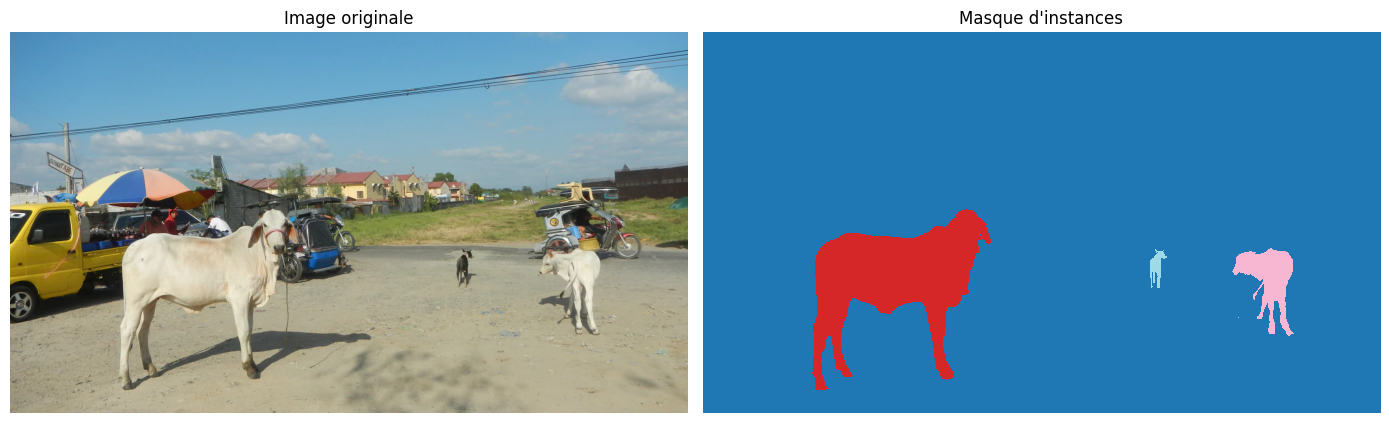

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

pair = instance_pairs[0]

image = np.array(Image.open(pair["image"]).convert("RGB"))
mask = np.array(Image.open(pair["mask"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(image)
axes[0].set_title("Image originale")
axes[0].axis("off")

axes[1].imshow(mask, cmap="tab20", interpolation="nearest")
axes[1].set_title("Masque d'instances")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 4. Séparation des données : entraînement, validation et test

Dans la première préparation des données, nous avions **60 images**, réparties selon les proportions suivantes :
- **70 % Train** : 42 images
- **15 % Validation** : 9 images
- **15 % Test** : 9 images

Pour la segmentation d'instances, seules **46 images sur 60** possèdent des annotations d'instances.

Nous avons donc :
1. Réutilisé la séparation déjà enregistrée dans `split_manifest.csv`.
2. Retiré les 14 images sans annotations d'instances.
3. Conservé chaque image restante dans son ensemble d'origine.

Nous obtenons ainsi :
- **Train : 33 images (71,74 %)**
- **Validation : 5 images (10,87 %)**
- **Test : 8 images (17,39 %)**

Les pourcentages sont différents de 70/15/15 parce que nous avons retiré certaines images, **sans refaire le split**.

Cette méthode permet de garder une séparation cohérente entre les différents modèles et de limiter les risques de fuite de données.

In [4]:
import pandas as pd

manifest_path = Path(
    "/content/drive/MyDrive/deep learning P/split_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

# Associer chaque image à son ensemble
split_map = {
    Path(str(row["image"])).name: row["split"]
    for _, row in manifest.iterrows()
}

# Réutiliser les mêmes ensembles pour les instances
for pair in instance_pairs:
    pair["split"] = split_map.get(pair["image"].name)

# Vérifier la répartition
for split in ["train", "validation", "test"]:
    count = sum(p["split"] == split for p in instance_pairs)
    print(f"{split} : {count} images")

print("Images sans split :", sum(p["split"] is None for p in instance_pairs))

train : 33 images
validation : 5 images
test : 8 images
Images sans split : 0


## 5. Prétraitement des images et des masques

Nous préparons les images et les masques pour la segmentation d'instances.

- **Resize :** nous utilisons une taille de 256 × 256 avec padding pour conserver les proportions des objets.
- **Normalization :** nous divisons les valeurs RGB par 255 pour obtenir des valeurs entre 0 et 1.
- **Masques :** nous appliquons le même redimensionnement, sans modifier les identifiants des obstacles.

Nous utilisons l'interpolation bilinéaire pour les images et l'interpolation nearest neighbor pour les masques, afin de ne pas créer de nouveaux identifiants.

In [5]:
import numpy as np
from PIL import Image, ImageOps

IMG_SIZE = (256, 256)

def preprocess_instance_image(image_path):
    image = Image.open(image_path).convert("RGB")

    image = ImageOps.pad(
        image,
        IMG_SIZE,
        method=Image.Resampling.BILINEAR,
        color=(0, 0, 0)
    )

    return np.asarray(image, dtype=np.float32) / 255.0


def preprocess_instance_mask(mask_path):
    mask = Image.open(mask_path)

    mask = ImageOps.pad(
        mask,
        IMG_SIZE,
        method=Image.Resampling.NEAREST,
        color=0
    )

    return np.asarray(mask)


# Vérification sur un exemple
pair = instance_pairs[0]

image_processed = preprocess_instance_image(pair["image"])
mask_processed = preprocess_instance_mask(pair["mask"])

print("Image :", image_processed.shape)
print("Valeurs image :", image_processed.min(), image_processed.max())

print("Masque :", mask_processed.shape)
print("Identifiants avant :", np.unique(np.array(Image.open(pair["mask"]))))
print("Identifiants après :", np.unique(mask_processed))

Image : (256, 256, 3)
Valeurs image : 0.0 0.9843137
Masque : (256, 256)
Identifiants avant : [0 1 2 3]
Identifiants après : [0 1 2 3]


### 5.1. Vérification du prétraitement sur toutes les images

Nous vérifions que le redimensionnement conserve les identifiants des obstacles dans les 46 masques.

Cette étape est importante, car certains obstacles peuvent être très petits et disparaître après le redimensionnement.

Nous vérifions également que les images et les masques ont les bonnes dimensions.

In [6]:
problemes = []
total_avant = 0
total_apres = 0

for pair in instance_pairs:
    image = preprocess_instance_image(pair["image"])
    mask_avant = np.array(Image.open(pair["mask"]))
    mask_apres = preprocess_instance_mask(pair["mask"])

    ids_avant = set(np.unique(mask_avant)) - {0}
    ids_apres = set(np.unique(mask_apres)) - {0}

    total_avant += len(ids_avant)
    total_apres += len(ids_apres)

    if (
        image.shape != (256, 256, 3)
        or mask_apres.shape != (256, 256)
        or ids_avant != ids_apres
    ):
        problemes.append({
            "image": pair["image"].name,
            "ids_perdus": sorted(ids_avant - ids_apres),
            "ids_ajoutes": sorted(ids_apres - ids_avant)
        })

print("Images vérifiées :", len(instance_pairs))
print("Instances avant Resize :", total_avant)
print("Instances après Resize :", total_apres)
print("Images avec problème :", len(problemes))

for probleme in problemes:
    print(probleme)

Images vérifiées : 46
Instances avant Resize : 201
Instances après Resize : 201
Images avec problème : 0


## 6. Transformation des labels et création des bounding boxes

Pour entraîner Mask R-CNN, nous devons préparer chaque obstacle séparément.

Nous allons :
- Créer un masque binaire pour chaque obstacle.
- Attribuer le label 1 à chaque obstacle (anomalie).
- Calculer une bounding box qui entoure chaque obstacle.

Les bounding boxes sont représentées par quatre coordonnées :
(xmin, ymin, xmax, ymax).

Nous commençons par vérifier le résultat sur une image.

In [7]:
# Premier exemple
pair = instance_pairs[0]
mask = preprocess_instance_mask(pair["mask"])

# Identifiants des obstacles (sans le fond)
instance_ids = np.unique(mask)
instance_ids = instance_ids[instance_ids != 0]

masks = []
boxes = []

for obj_id in instance_ids:
    # Un masque binaire pour chaque obstacle
    binary_mask = (mask == obj_id).astype(np.uint8)

    # Trouver les pixels de l'obstacle
    ys, xs = np.where(binary_mask == 1)

    # Coordonnées du rectangle (limites supérieures exclusives)
    xmin, xmax = xs.min(), xs.max() + 1
    ymin, ymax = ys.min(), ys.max() + 1

    masks.append(binary_mask)
    boxes.append([xmin, ymin, xmax, ymax])

# Tous les obstacles appartiennent à la classe anomalie
labels = np.ones(len(instance_ids), dtype=np.int64)

print("Nombre d'obstacles :", len(instance_ids))
print("Dimensions des masques :", np.array(masks).shape)
print("Labels :", labels)
print("Bounding boxes :")
for box in boxes:
    print(box)

Nombre d'obstacles : 3
Dimensions des masques : (3, 256, 256)
Labels : [1 1 1]
Bounding boxes :
[np.int64(41), np.int64(123), np.int64(109), np.int64(191)]
[np.int64(200), np.int64(138), np.int64(223), np.int64(171)]
[np.int64(169), np.int64(139), np.int64(175), np.int64(153)]


### 6.1. Visualisation des bounding boxes

Nous affichons les rectangles autour des obstacles sur l'image.

Cette vérification permet de confirmer que les bounding boxes sont bien placées et correspondent aux masques individuels.

Chaque rectangle représente un obstacle différent.

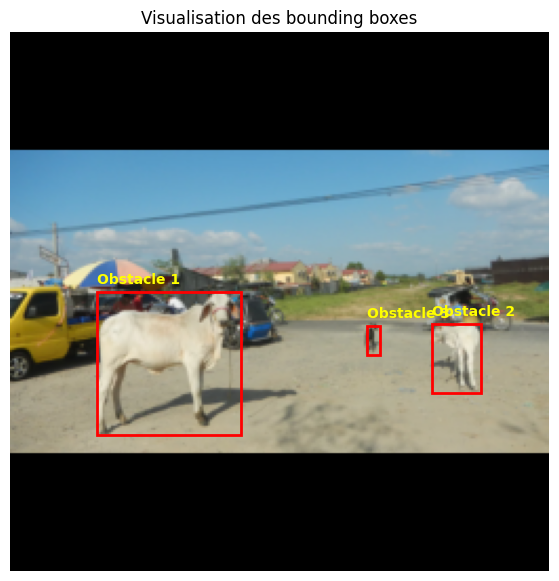

In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image = preprocess_instance_image(pair["image"])

fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(image)

for i, (xmin, ymin, xmax, ymax) in enumerate(boxes):
    rect = patches.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)
    ax.text(
        xmin, max(0, ymin - 4),
        f"Obstacle {i + 1}",
        color="yellow",
        fontsize=10,
        weight="bold"
    )

ax.set_title("Visualisation des bounding boxes")
ax.axis("off")

plt.show()

## 7. Création du Dataset PyTorch

Nous créons un Dataset pour préparer automatiquement les 46 images et leurs annotations.

Pour chaque image, le Dataset retourne :
- L'image sous forme de tenseur PyTorch.
- Un masque binaire pour chaque obstacle.
- Une bounding box pour chaque obstacle.
- Un label égal à 1 pour chaque obstacle (anomalie).

Nous ajoutons également les informations nécessaires à Mask R-CNN, comme la surface des rectangles et les identifiants des images.

Le nombre d'obstacles peut être différent d'une image à une autre.

In [11]:
import torch
from torch.utils.data import Dataset

class RoadAnomalyInstanceDataset(Dataset):

    def __init__(self, pairs, augment=False):
      self.pairs = pairs
      self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        pair = self.pairs[idx]

        # Prétraitement
        image = preprocess_instance_image(pair["image"])
        mask = preprocess_instance_mask(pair["mask"])
        # Augmentation uniquement si elle est activée
        if self.augment:
            image, mask = augment_instance(image, mask)

        # Identifiants des obstacles
        ids = np.unique(mask)
        ids = ids[ids != 0]

        masks = []
        boxes = []

        for obj_id in ids:
            binary_mask = (mask == obj_id).astype(np.uint8)
            ys, xs = np.where(binary_mask == 1)

            xmin, xmax = xs.min(), xs.max() + 1
            ymin, ymax = ys.min(), ys.max() + 1

            masks.append(binary_mask)
            boxes.append([xmin, ymin, xmax, ymax])

        # Conversion en tenseurs
        image = torch.from_numpy(image.copy()).permute(2, 0, 1)

        target = {
            "boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.ones(len(ids), dtype=torch.int64),
            "masks": torch.tensor(np.stack(masks), dtype=torch.uint8)
                     if masks else torch.zeros((0, 256, 256), dtype=torch.uint8),
            "image_id": torch.tensor(idx),
            "iscrowd": torch.zeros(len(ids), dtype=torch.int64)
        }

        boxes_tensor = target["boxes"]
        target["area"] = (
            (boxes_tensor[:, 2] - boxes_tensor[:, 0])
            * (boxes_tensor[:, 3] - boxes_tensor[:, 1])
        )

        return image, target


# Vérification sur la première image
dataset = RoadAnomalyInstanceDataset(instance_pairs)

image, target = dataset[0]

print("Images dans le Dataset :", len(dataset))
print("Dimensions de l'image :", image.shape)
print("Dimensions des masques :", target["masks"].shape)
print("Dimensions des boxes :", target["boxes"].shape)
print("Labels :", target["labels"])

Images dans le Dataset : 46
Dimensions de l'image : torch.Size([3, 256, 256])
Dimensions des masques : torch.Size([3, 256, 256])
Dimensions des boxes : torch.Size([3, 4])
Labels : tensor([1, 1, 1])


## 8. Augmentation des données

Pour limiter le surapprentissage, nous appliquons trois transformations aux images d'entraînement :
- Retournement horizontal de l'image et des masques.
- Variation de luminosité.
- Variation de contraste.

Les bounding boxes sont recalculées après les transformations.

L'augmentation est appliquée uniquement au Train (33 images), pas à la Validation ni au Test.

In [18]:
import random
from PIL import ImageEnhance

def augment_instance(image, mask):
    # Retournement horizontal
    if random.random() < 0.5:
        image = np.flip(image, axis=1).copy()
        mask = np.flip(mask, axis=1).copy()

    # Variation de luminosité et contraste
    image_pil = Image.fromarray((image * 255).astype(np.uint8))

    brightness = random.uniform(0.85, 1.15)
    contrast = random.uniform(0.85, 1.15)

    image_pil = ImageEnhance.Brightness(image_pil).enhance(brightness)
    image_pil = ImageEnhance.Contrast(image_pil).enhance(contrast)

    image = np.asarray(image_pil, dtype=np.float32) / 255.0

    return image, mask

train_pairs = [p for p in instance_pairs if p["split"] == "train"]
val_pairs = [p for p in instance_pairs if p["split"] == "validation"]
test_pairs = [p for p in instance_pairs if p["split"] == "test"]

train_dataset = RoadAnomalyInstanceDataset(train_pairs, augment=True)
val_dataset = RoadAnomalyInstanceDataset(val_pairs, augment=False)
test_dataset = RoadAnomalyInstanceDataset(test_pairs, augment=False)

print("Train :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test :", len(test_dataset))

image, target = train_dataset[0]

print("Image :", image.shape)
print("Masques :", target["masks"].shape)
print("Boxes :", target["boxes"].shape)


Train : 33
Validation : 5
Test : 8
Image : torch.Size([3, 256, 256])
Masques : torch.Size([3, 256, 256])
Boxes : torch.Size([3, 4])


## 9. Création des DataLoaders

Nous créons trois DataLoaders pour l'entraînement, la validation et le test.

- **Train :** 33 images, mélangées à chaque époque, avec augmentation.
- **Validation :** 5 images, sans augmentation.
- **Test :** 8 images, sans augmentation.

Nous utilisons un batch size de 2 pour commencer.

Comme chaque image peut contenir un nombre différent d'obstacles, nous utilisons `collate_fn` pour regrouper les images et leurs annotations sans perdre ces informations.

In [14]:
from torch.utils.data import DataLoader

# Regrouper les images et les annotations
def collate_fn(batch):
    return tuple(zip(*batch))

BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

# Vérification
images, targets = next(iter(train_loader))

print("Nombre de batches Train :", len(train_loader))
print("Nombre de batches Validation :", len(val_loader))
print("Nombre de batches Test :", len(test_loader))

print("Images dans le premier batch :", len(images))
print("Dimensions première image :", images[0].shape)
print("Dimensions des masques :", targets[0]["masks"].shape)
print("Dimensions des boxes :", targets[0]["boxes"].shape)

Nombre de batches Train : 17
Nombre de batches Validation : 3
Nombre de batches Test : 4
Images dans le premier batch : 2
Dimensions première image : torch.Size([3, 256, 256])
Dimensions des masques : torch.Size([1, 256, 256])
Dimensions des boxes : torch.Size([1, 4])


## 10. Vérification finale des données

Nous vérifions que les 46 images sont correctement préparées pour Mask R-CNN.

Pour chaque image, nous contrôlons :
- Les dimensions et les valeurs des images.
- La présence et la cohérence des masques individuels.
- La validité des bounding boxes.
- La correspondance entre les masques, les boxes et les labels.

Cette vérification permet de détecter d'éventuelles erreurs avant l'entraînement.

In [15]:
import torch

erreurs = []
total_instances = 0

for nom, dataset in [
    ("Train", train_dataset),
    ("Validation", val_dataset),
    ("Test", test_dataset)
]:
    for i in range(len(dataset)):
        image, target = dataset[i]

        boxes = target["boxes"]
        masks = target["masks"]
        labels = target["labels"]

        n = len(labels)
        total_instances += n

        valide = (
            image.shape == (3, 256, 256)
            and torch.isfinite(image).all().item()
            and image.min().item() >= 0
            and image.max().item() <= 1
            and masks.shape == (n, 256, 256)
            and boxes.shape == (n, 4)
            and torch.all(labels == 1).item()
            and torch.isfinite(boxes).all().item()
            and torch.all(boxes[:, 0] >= 0).item()
            and torch.all(boxes[:, 1] >= 0).item()
            and torch.all(boxes[:, 2] <= 256).item()
            and torch.all(boxes[:, 3] <= 256).item()
            and torch.all(boxes[:, 2] > boxes[:, 0]).item()
            and torch.all(boxes[:, 3] > boxes[:, 1]).item()
        )

        # Vérifier que les masques sont binaires et non vides
        if n > 0:
            valide = valide and (
                torch.all((masks == 0) | (masks == 1)).item()
                and torch.all(masks.flatten(1).sum(1) > 0).item()
            )

        if not valide:
            erreurs.append((nom, i))

print("Images vérifiées :", sum(
    len(d) for d in [train_dataset, val_dataset, test_dataset]
))
print("Instances vérifiées :", total_instances)
print("Images avec erreurs :", len(erreurs))
print("Détails des erreurs :", erreurs)

Images vérifiées : 46
Instances vérifiées : 201
Images avec erreurs : 0
Détails des erreurs : []


## 11. Conclusion

Nous avons préparé les données pour la segmentation d'instances avec Mask R-CNN.

Les principales étapes réalisées sont :
- Chargement et vérification des 46 images annotées.
- Réutilisation des ensembles Train, Validation et Test.
- Redimensionnement et normalisation des images.
- Création des masques individuels et des bounding boxes.
- Augmentation des données d'entraînement.
- Création du Dataset et des DataLoaders PyTorch.

La vérification finale confirme que les 46 images et les 201 instances sont correctement préparées, sans erreur détectée.

Les données sont maintenant prêtes pour commencer les expérimentations avec Mask R-CNN.